<a href="https://colab.research.google.com/github/gaboruiz12/Modelado-de-sistemas/blob/main/PIA_Modelado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

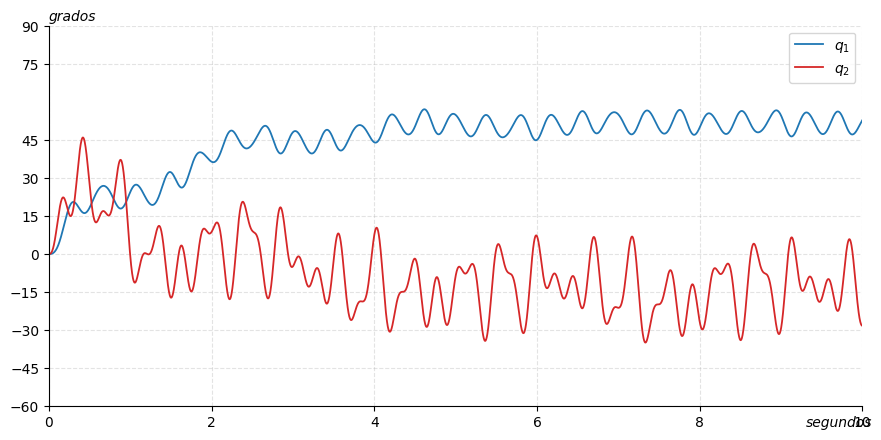

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt


def signo(val):
    return np.sign(val)


def cap5_robot2gdl(t, x):

    q = np.array([x[0], x[1]], dtype=float)
    qp = np.array([x[2], x[3]], dtype=float)

    M = np.array([
        [3.117 + 0.2 * np.cos(q[1]), 0.108 + 0.1 * np.cos(q[1])],
        [0.108 + 0.1 * np.cos(q[1]), 0.108]
    ], dtype=float)

    C = np.array([
        [-0.2 * np.sin(q[1]) * qp[1], -0.1 * np.sin(q[1]) * qp[1]],
        [0.1 * np.sin(q[1]) * qp[0], 0.0]
    ], dtype=float)

    par_grav = np.array([
        39.3 * np.sin(q[0]) + 1.95 * np.sin(q[0] + q[1]),
        1.95 * np.sin(q[0] + q[1])
    ], dtype=float)

    fr = np.array([
        1.86 * qp[0] + 1.93 * signo(qp[0]),
        0.16 * qp[1] + 0.3 * signo(qp[1])
    ], dtype=float)

    tau = np.array([
        (1.0 - np.exp(-0.8 * t)) * 32.0 + 56.0 * np.sin(16.0 * t + 0.1) + 12.0 * np.sin(20.0 * t + 0.15),
        (1.0 - np.exp(-1.8 * t)) * 1.2 + 8.0 * np.sin(26.0 * t + 0.08) + 2.0 * np.sin(12.0 * t + 0.34)
    ], dtype=float)

    q2p = np.linalg.solve(M, tau - C @ qp - par_grav - fr)

    return np.array([qp[0], qp[1], q2p[0], q2p[1]], dtype=float)


def main():
    ti = 0.0
    h = 0.0025
    tf = 10.0
    ts = np.arange(ti, tf + h / 2.0, h)
    x0 = np.zeros(4, dtype=float)

    sol = solve_ivp(
        fun=cap5_robot2gdl,
        t_span=(ti, tf),
        y0=x0,
        method="RK45",
        t_eval=ts,
        first_step=h,
        max_step=h,
        rtol=1e-3,
        atol=1e-6,
    )

    t = sol.t
    q1_deg = np.rad2deg(sol.y[0])
    q2_deg = np.rad2deg(sol.y[1])

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(t, q1_deg, color="#1f77b4", linewidth=1.3, label=r"$q_1$")
    ax.plot(t, q2_deg, color="#d62728", linewidth=1.3, label=r"$q_2$")

    ax.set_xlim(0, 10)
    ax.set_xticks([0, 2, 4, 6, 8, 10])
    ax.set_yticks([-60, -45, -30, -15, 0, 15, 30, 45, 75, 90])

    ax.text(0.0, ax.get_ylim()[1] + 2, "grados", style="italic", fontsize=10)
    ax.text(9.3, ax.get_ylim()[0] - 8, "segundos", style="italic", fontsize=10)

    ax.legend(loc="best", frameon=True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, linestyle="--", alpha=0.35)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()